# King County House Prices Project

Your task is to **predict the sale price of a house** in King County with a regression model, and to **tune** the model with cross-validation. In the project you combine the methods you already know into one complete analysis.

The task below follows the steps of a machine learning project, in a single pass:

![The project in one pass, from top to bottom: 1. goal and metric, 2. get the data, 3. a train-test split into training data and locked test data. Steps 4 and 5 (explore, baselines) use only the training data. Steps 6 and 7 form the model selection loop: feature engineering, set hyperparameters, train model(s) and calculate the cross-validation score, then repeat. In step 8, the test data is unlocked and the models are scored on the test set](assets/king_county_project_workflow.png)

# Data Description

King County covers Seattle and its surroundings. The data ships with this repository as **two tables**:

- `data/king_county_house_sales.csv`: one row per sale, with the date and the price
- `data/king_county_house_details.csv`: one row per house, with its physical attributes

`01_loading_the_data.ipynb` guides you through combining them into one table.

| Column | Table | Description |
| :-- | :-- | :-- |
| `date` | sales | date the house was sold |
| `price` | sales | sale price in dollars, the prediction target |
| `house_id` | sales | identifier of the house, matches `id` in the details table |
| `id` | sales | identifier of the sale |
| `id` | details | unique identifier for a house |
| `bedrooms` | details | number of bedrooms |
| `bathrooms` | details | number of bathrooms |
| `sqft_living` | details | square footage of the home |
| `sqft_lot` | details | square footage of the lot |
| `floors` | details | total floors (levels) in the house |
| `waterfront` | details | whether the house has a view to a waterfront |
| `view` | details | quality of the view |
| `condition` | details | overall condition of the house |
| `grade` | details | overall grade given to the housing unit, based on the King County grading system |
| `sqft_above` | details | square footage of the house apart from the basement |
| `sqft_basement` | details | square footage of the basement |
| `yr_built` | details | year the house was built |
| `yr_renovated` | details | year the house was renovated |
| `zipcode` | details | zip code |
| `lat` | details | latitude coordinate |
| `long` | details | longitude coordinate |
| `sqft_living15` | details | square footage of the interior living space of the nearest 15 neighbours |
| `sqft_lot15` | details | square footage of the land lots of the nearest 15 neighbours |

## Task

1. **Set your goal.** Decide which metric you use to judge the model, and explain why.
2. **Get the data.** Complete `01_loading_the_data.ipynb` first: it combines the two tables and saves the result as `data/eda.csv`, which you load here.
3. **Split the data into a training and a test set.** Use `train_test_split` once. Choose the size of the test set with `test_size`, and fix the `random_state`, so that you get the same split every time you run the notebook. Keep the features and the target together: the result should be two DataFrames, `df_train` and `df_test`, that both still contain the `price` column. You do not need a separate validation set: in step 7, cross-validation on the training set takes its place. Do not look at `df_test` until step 8.
4. **Explore the training set.** Which columns are related to the price, and which one most strongly? Which columns are skewed, which values are missing, and which features contain the same information?

> [!IMPORTANT]
> **Keep a record of every change you make to the training data by hand.** In step 8 you apply exactly the same changes to the test set. This covers, for example, a new column such as the age of the house at sale, or dropping the identifiers `id` and `house_id` and the `date` column. Transformations inside your `Pipeline` (imputing, scaling, encoding) are applied to the test set automatically, with the values learned on the training data.

5. **Separate the features from the target, and build two baselines.** Split `df_train` into `X_train` and `y_train`; the test set stays untouched until step 8. Then build two simple models that your models have to beat:
    - a **mean baseline** with [`DummyRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html), which predicts the mean price of the training set for every house, and
    - a **rule-based baseline** built from the column most strongly related to the price in step 4. Learn the values of the rule on the training data.
6. **Build a preprocessing pipeline and train a linear model.** Put every transformation into a `Pipeline` with a `ColumnTransformer`, so that it is fitted on the training data only, and train a regularised linear model, for example `Ridge`, with as many features as possible.
7. **Tune and compare models with cross-validation.** Train and tune at least two models, for example `Ridge` on the original features and on polynomial features: first a wide `RandomizedSearchCV`, then a narrow `GridSearchCV` around what it found. Choose the best model by its cross-validated score. **Save every model in its own variable** (and the values of your rule), so that you can evaluate all of them in the last step.
8. **Prepare the test set and evaluate all models at the very end.** First apply to `df_test` the changes you made by hand to the training data, and split it into `X_test` and `y_test`. Then calculate the **training and the test scores of every model** with your chosen metric, including both baselines, and collect them in **one table**: one row per model, with columns for the training and the test scores. Compare the models: which ones beat the baselines, and how large is the difference between training and test scores? Finally, **analyse the residuals** of your best model: for which houses is it wrong, and how large are the errors?

In [4]:
# Import the libraries you need for this project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

1. 
    - **Goal:** Predict the sale price of houses in King County.
    - **Metric:** I will use RMSE (Root Mean Squared Error).
    - **Why:** RMSE is measured in the same units as the target variable (dollars), which makes it easy to interpret. Moreover, squaring the errors before averaging means RMSE penalizes large errors more heavily than MAE. In real estate, predicting a house price off by $500,000 is much worse than being off by $10,000 on 50 different houses, so we want our model to avoid huge mistakes.

2. - Get the data
3. - Split the data

In [5]:
# 2: Get the data
df = pd.read_csv("data/eda.csv")

# 3: Split the data
# split the data into train (80%) and test (20%) sets.
# setting random_state=42 ensures that the split remains the same when the notebook is restarted.
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)

print(f"Training set: {df_train.shape[0]} rows")
print(f"Test set:     {df_test.shape[0]} rows")

# create a copy of the training dataset for analysis (to avoid accidentally modifying the original).
train_eda = df_train.copy()

Training set: 17277 rows
Test set:     4320 rows


4. - Exploration (Correlation, Missing Values, Skewness)

In [ ]:
# 4.a) Explore the training set

# take only the numerical columns
numeric_df = train_eda.select_dtypes(include=[np.number])

# which columns have the strongest correlation with price?
corr_with_price = numeric_df.corr()['price'].sort_values(ascending=False)

print(" ===== Top 5 factors with the greatest impact on price: =====")
print(corr_with_price.head(6)[1:]) # skip the price itself

print("\n===== Columns with missing values: =====")
# which values ​​are missing?
missing = train_eda.isnull().sum()
print(missing[missing > 0])

print("\n===== Top 5 most skewed columns: =====")
# which columns are skewed (skewed)? (Value > 1 indicates strong skewness)
skewness = numeric_df.skew().sort_values(ascending=False)
print(skewness.head(5))

 ===== Top 5 factors with the greatest impact on price: =====
sqft_living      0.701778
grade            0.670040
sqft_above       0.603072
sqft_living15    0.588622
bathrooms        0.529378
Name: price, dtype: float64

===== Columns with missing values: =====
waterfront       1907
view               53
sqft_basement     356
yr_renovated     3069
dtype: int64

===== Top 5 most skewed columns: =====
sqft_lot        13.370248
waterfront      11.282146
sqft_lot15       8.897467
yr_renovated     4.583855
price            3.951774
dtype: float64


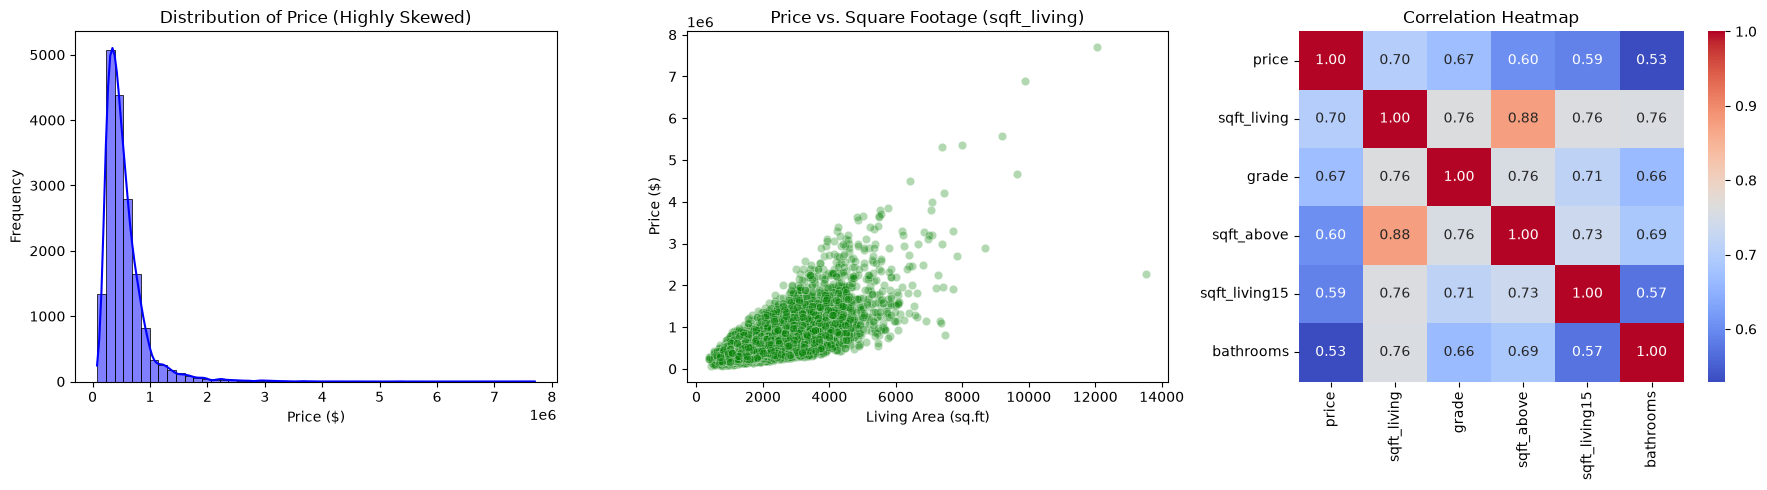

In [18]:
# visualization

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Skewness of the target variable (Price)
sns.histplot(train_eda['price'], bins=50, kde=True, ax=axes[0], color='blue')
axes[0].set_title('Distribution of Price (Highly Skewed)')
axes[0].set_xlabel('Price ($)')
axes[0].set_ylabel('Frequency')

# Relationship between the strongest feature and price
sns.scatterplot(data=train_eda, x='sqft_living', y='price', alpha=0.3, ax=axes[1], color='green')
axes[1].set_title('Price vs. Square Footage (sqft_living)')
axes[1].set_xlabel('Living Area (sq.ft)')
axes[1].set_ylabel('Price ($)')

# Correlation Heatmap (Top features)
top_features = corr_with_price.head(6).index # price + top 5
sns.heatmap(train_eda[top_features].corr(), annot=True, cmap='coolwarm', fmt=".2f", ax=axes[2])
axes[2].set_title('Correlation Heatmap')

plt.tight_layout()
plt.show()

4. - Manual changes

In [8]:
def wrangle_data(df):
    """
    This function applies all manual changes. 
    We run `df_train` through it now, and `df_test` at the very end.
    """
    # making a copy so as not to break the original.
    df = df.copy()
    
    # convert the sale date to datetime format
    df['date'] = pd.to_datetime(df['date'])
    
    # FEATURE ENGINEERING: Creating a 'house age at the time of sale' column
    df['age_at_sale'] = df['date'].dt.year - df['yr_built']
    
    # Removing junk columns:
    # house_id, id, id_details - just numbers, they don’t affect the price.
    # date - have already extracted the useful information (age_at_sale) from it, the regression date itself is not needed.
    cols_to_drop = ['house_id', 'id_details', 'id', 'date']
    
    df = df.drop(columns=cols_to_drop, errors='ignore')
    
    return df

# Applying the function to the training data!
df_train_cleaned = wrangle_data(df_train)

print(f"Size of the training dataset BEFORE cleaning:    {df_train.shape}")
print(f"Size of the training dataset AFTER cleaning: {df_train_cleaned.shape}")

Size of the training dataset BEFORE cleaning:    (17277, 23)
Size of the training dataset AFTER cleaning: (17277, 20)


5.  
    - Extracting the 'price' column into a separate variable, `y_train` (this is the target). The remaining columns will become `X_train` (the features).
    - Create a "mean baseline"—a dummy model that doesn’t "think" but simply always predicts the average price (to serve as a point of comparison).
    - Create a rule-based baseline—a model built on a simple rule. Since `sqft_living` has the strongest influence, we’ll calculate the average price per square foot and then multiply the area of ​​any given house by that figure!

In [10]:
# Separate the features (X) and the target variable (y)
X_train = df_train_cleaned.drop(columns=['price'])
y_train = df_train_cleaned['price']

# MEAN BASELINE: Training DummyRegressor
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train, y_train)
print("Mean baseline model trained!")

# RULE-BASED BASELINE: Create a rule based on sqft_living(max correlation with price)
# Calculate the average price per square foot (using only the training data!)
price_per_sqft = (y_train / X_train['sqft_living']).mean()
print(f"Rule learned: {price_per_sqft:.2f} dollars per sq.ft.")

# Create a simple function (our manual model) that makes predictions based on this rule.
def rule_based_predict(X_data):
    return X_data['sqft_living'] * price_per_sqft

print("Rule-based baseline created!")

Mean baseline model trained!
Rule learned: 264.14 dollars per sq.ft.
Rule-based baseline created!


In [11]:
# --- BASELINE REVIEW ---
# predicts
dummy_preds = dummy_model.predict(X_train)
rule_preds = rule_based_predict(X_train)

# Calculate error (RMSE)
dummy_rmse = root_mean_squared_error(y_train, dummy_preds)
rule_rmse = root_mean_squared_error(y_train, rule_preds)

print(f"Error Mean Baseline: ${dummy_rmse:,.0f} (By how much we err on average if we always predict the mean price)")
print(f"Error Rule-Based:    ${rule_rmse:,.0f} (By how much we err if we multiply the area by {price_per_sqft:.0f}$)")

Error Mean Baseline: $368,958 (By how much we err on average if we always predict the mean price)
Error Rule-Based:    $263,513 (By how much we err if we multiply the area by 264$)


6. - Build a preprocessing pipeline and train a linear model

In [13]:
# Preprocessing Pipeline and Linear Model

# Categorizing columns by type
# zipcode - actually, this is a category
categorical_cols = ['zipcode'] 

# all other columns as numerical
numeric_cols = [col for col in X_train.columns if col not in categorical_cols]


# creating a transformer for numerical data (filling in missing values ​​with the median, then scaling)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# creating a transformer for categorical data (imputing missing values, then applying One-Hot encoding)
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')) # ignore - it’s needed in case new zip codes appear in the test set
])

# combine everything into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

# creating the final pipeline: Data processing + Ridge model
pipeline_ridge = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

# train a Pipeline! It will automatically fill in missing values, encode the zipcode, and train the model.
pipeline_ridge.fit(X_train, y_train)

# check how much better it is than the baselines!
ridge_preds = pipeline_ridge.predict(X_train)
ridge_rmse = root_mean_squared_error(y_train, ridge_preds)

print("Pipeline successfully trained!")
print(f"Error of our first ML model: ${ridge_rmse:,.0f}")

Pipeline successfully trained!
Error of our first ML model: $160,250


7. - Tuning a standard Ridge model

In [14]:
# Cross-Validation & Tuning (Basic Ridge)

# define a grid of parameters (adjusting the "knob" for alpha in Ridge regression)
param_grid_ridge = {
    'model__alpha': [0.1, 1.0, 10.0, 50.0, 100.0]
}

# set up GridSearchCV. cv=5 means that the data is split into 5 parts for validation.
# scoring='neg_root_mean_squared_error' — scikit-learn prefers to maximize scores, which is why the error is represented as a negative value.
grid_ridge = GridSearchCV(
    pipeline_ridge, 
    param_grid_ridge, 
    cv=5, 
    scoring='neg_root_mean_squared_error',
    n_jobs=-1 # use all processor cores for speed
)

# starting
grid_ridge.fit(X_train, y_train)

# save the BEST standard model into a separate variable
best_ridge_model = grid_ridge.best_estimator_
best_ridge_cv_rmse = -grid_ridge.best_score_ # removing the minus sign

print(f"Best alpha parameter for the baseline model: {grid_ridge.best_params_['model__alpha']}")
print(f"Cross-validation RMSE: ${best_ridge_cv_rmse:,.0f}")

Best alpha parameter for the baseline model: 0.1
Cross-validation RMSE: $161,676


Here, the RMSE increased slightly compared to the previous step. In step 6, we looked at the error "on the same data used for training" (which is self-deception), whereas here, thanks to cross-validation, we see an honest estimate of the error.

7. - Building and tuning a Polynomial Ridge model

        let’s add magic: `PolynomialFeatures`. This will create new columns (for example, the square of the area). Since this results in a large number of new columns, we’ll first use a "broad search" (`RandomizedSearchCV`) to quickly narrow down the general area, followed by a "focused search" (`GridSearchCV`).

In [ ]:
from sklearn.compose import TransformedTargetRegressor

# make a slight change to the polynomial transformer (adding `interaction_only=True` — this is optional; feel free to remove it if the results get worse)
poly_numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('poly', PolynomialFeatures(degree=2, interaction_only=False, include_bias=False)), 
    ('scaler', StandardScaler())
])

poly_preprocessor = ColumnTransformer(
    transformers=[
        ('num', poly_numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

# building a pipeline with Ridge
base_pipeline_poly = Pipeline(steps=[
    ('preprocessor', poly_preprocessor),
    ('model', Ridge())
])

# wrap the entire pipeline in a TransformedTargetRegressor!
# it will automatically take the logarithm of the price during training and apply the exponential function during prediction.
log_target_pipeline = TransformedTargetRegressor(
    regressor=base_pipeline_poly,
    func=np.log1p,         # we take the logarithm of y_train
    inverse_func=np.expm1  # converting back into dollars for predictions
)

# Configuring settings
# IMPORTANT: 
# regressor -> model -> alpha
param_dist = {
    'regressor__model__alpha': loguniform(0.01, 1000.0) # extended the range downward
}

# Increased n_iter to 50
random_search_poly = RandomizedSearchCV(
    log_target_pipeline,
    param_distributions=param_dist,
    n_iter=50, # searching more thoroughly
    cv=3,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1
)

print("Starting deep random search (RandomizedSearchCV) ...")
random_search_poly.fit(X_train, y_train)

best_random_alpha = random_search_poly.best_params_['regressor__model__alpha']
print(f"RandomSearch found the approximate range for alpha: {best_random_alpha:.4f}")

# creating a narrow grid, capturing a slightly wider range of options.
param_grid_poly = {
    'regressor__model__alpha': [
        best_random_alpha * 0.1,
        best_random_alpha * 0.5, 
        best_random_alpha, 
        best_random_alpha * 2.0,
        best_random_alpha * 5.0
    ]
}

grid_poly = GridSearchCV(
    log_target_pipeline,
    param_grid_poly,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

print("Starting narrow search (GridSearchCV)...")
grid_poly.fit(X_train, y_train)

# Save best model
best_poly_model = grid_poly.best_estimator_
best_poly_cv_rmse = -grid_poly.best_score_

print(f"Best alpha parameter for Polynomial Ridge: {grid_poly.best_params_['regressor__model__alpha']:.4f}")
print(f"Cross-validation RMSE (Poly with Log Target): ${best_poly_cv_rmse:,.0f}")

Starting deep random search (RandomizedSearchCV) ...
RandomSearch found the approximate range for alpha: 0.0127
Starting narrow search (GridSearchCV)...
Best alpha parameter for Polynomial Ridge: 0.0013
Cross-validation RMSE (Poly with Log Target): $128,680


8. - Prepare the test set and evaluate all models

,Train RMSE,Test RMSE,Test MAE,Test R²
Model,,,,
1. Mean Baseline,"$368,958","$360,907","$231,542",-0.000
2. Rule-Based Baseline,"$263,513","$257,219","$169,716",0.492
3. Ridge (Linear),"$160,173","$161,780","$96,276",0.799
4. Ridge (Polynomial + Log),"$118,427","$117,893","$68,215",0.893


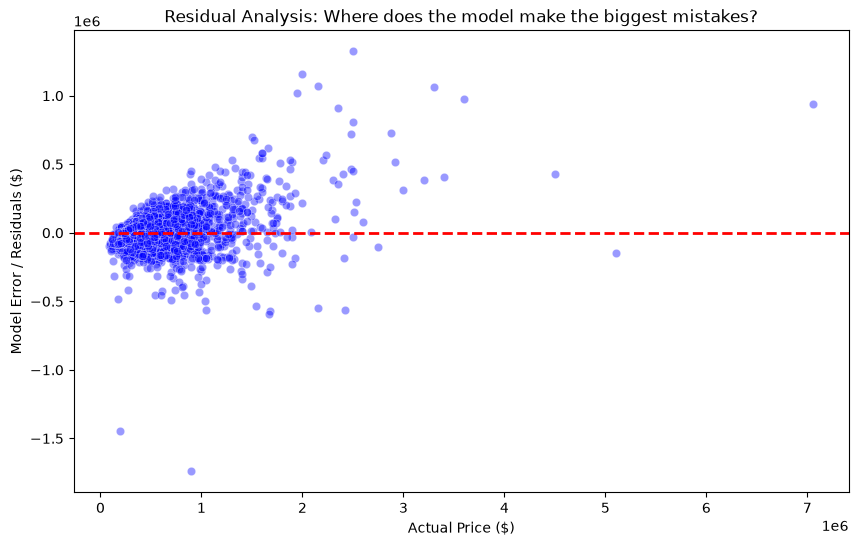


--- TOP 5 Houses with the Largest Errors ---


,price,predicted_price,error,sqft_living,grade,zipcode,bedrooms
21034,900000.0,2.641319e+06,-1.741319e+06,7120.0,12,98006,5.0
17305,190000.0,1.633783e+06,-1.443783e+06,710.0,5,98014,2.0
7304,2500000.0,1.177470e+06,1.322530e+06,3330.0,10,98006,4.0
6685,2000000.0,8.448904e+05,1.155110e+06,3900.0,12,98065,2.0
4031,2150000.0,1.077679e+06,1.072321e+06,4340.0,8,98004,8.0


In [20]:
# PREPARE TEST SET & EVALUATE ALL MODELS

# apply the exact same manual changes to the TEST set
df_test_cleaned = wrangle_data(df_test)

# separate features (X_test) and target (y_test)
X_test = df_test_cleaned.drop(columns=['price'])
y_test = df_test_cleaned['price']

# collect predictions from all models into a dictionary
models_dict = {
    "1. Mean Baseline": (dummy_model.predict(X_train), dummy_model.predict(X_test)),
    "2. Rule-Based Baseline": (rule_based_predict(X_train), rule_based_predict(X_test)),
    "3. Ridge (Linear)": (best_ridge_model.predict(X_train), best_ridge_model.predict(X_test)),
    "4. Ridge (Polynomial + Log)": (best_poly_model.predict(X_train), best_poly_model.predict(X_test))
}

# calculate metrics and build a summary table
results = []
for name, (train_preds, test_preds) in models_dict.items():
    train_rmse = root_mean_squared_error(y_train, train_preds)
    test_rmse = root_mean_squared_error(y_test, test_preds)
    test_mae = mean_absolute_error(y_test, test_preds)
    test_r2 = r2_score(y_test, test_preds)
    
    results.append({
        "Model": name,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,
        "Test MAE": test_mae,
        "Test R²": test_r2
    })

# display a formatted table
results_df = pd.DataFrame(results).set_index("Model")
results_df["Train RMSE"] = results_df["Train RMSE"].apply(lambda x: f"${x:,.0f}")
results_df["Test RMSE"] = results_df["Test RMSE"].apply(lambda x: f"${x:,.0f}")
results_df["Test MAE"] = results_df["Test MAE"].apply(lambda x: f"${x:,.0f}")
results_df["Test R²"] = results_df["Test R²"].round(3)

display(results_df)


# --- ANALYSE RESIDUALS ---
# predict with the best model
best_preds = best_poly_model.predict(X_test)

# Residuals = Actual Price - Predicted Price
residuals = y_test - best_preds

# plot Residuals
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=residuals, alpha=0.4, color='blue')
plt.axhline(0, color='red', linestyle='--', linewidth=2)
plt.xlabel("Actual Price ($)")
plt.ylabel("Model Error / Residuals ($)")
plt.title("Residual Analysis: Where does the model make the biggest mistakes?")
plt.show()

# find the TOP-5 houses with the largest errors
error_df = df_test.copy() # Using original test set to see all original columns
error_df['predicted_price'] = best_preds
error_df['error'] = residuals
error_df['abs_error'] = abs(residuals)

print("\n--- TOP 5 Houses with the Largest Errors ---")
top_5_errors = error_df.sort_values(by='abs_error', ascending=False).head(5)
display(top_5_errors[['price', 'predicted_price', 'error', 'sqft_living', 'grade', 'zipcode', 'bedrooms']])

8. **Final Evaluation and Residual Analysis**

    - **Which models beat the baselines?**
        
        Both machine learning models (Linear Ridge and Polynomial Ridge) significantly beat the baselines.
        The Mean Baseline had a huge test error (RMSE ~$361k), and our manual Rule-Based Baseline improved it to ~$257k. However, the Linear Ridge model reduced the error to ~$162k, and our champion model (Polynomial Ridge with a Log-transformed target) completely crushed the baselines with a Test RMSE of $117,893 and an outstanding R-squared of 0.893 (meaning it explains about 89% of the variance in house prices).



    - **How large is the difference between training and test scores?**
        
        For our best model, the difference is practically zero (Train RMSE is $118,427 vs. Test RMSE is $117,893). The fact that the test error is just as good as the training error proves that there is no overfitting. Our hyperparameter tuning and cross-validation worked perfectly, allowing the model to generalize excellently to unseen data.



    - **Residual Analysis: For which houses is it wrong, and how large are the errors?**
        
        Based on the scatter plot and the Top 5 error table, we can see the following:

        The model is highly accurate for standard houses priced under $1.5M (the points are tightly clustered around the zero-error line).

        As prices increase, the errors grow (forming a cone shape on the plot). The model struggles with ultra-luxury homes (Actual price > $2M), often underpredicting their value. Buyers of such homes pay massive premiums for subjective factors (exclusivity, custom architecture) that normal features like square footage cannot fully capture.

        The absolute largest error is a massive anomaly: a 7,120 sqft house with a luxury Grade of 12 that sold for only $900,000. The model logically predicted it should cost around $2.64M. The model's error here is ~$1.7M, but in reality, this sale price suggests a real-world outlier not captured in the data (such as a distress sale, family transaction, or severe hidden damage).